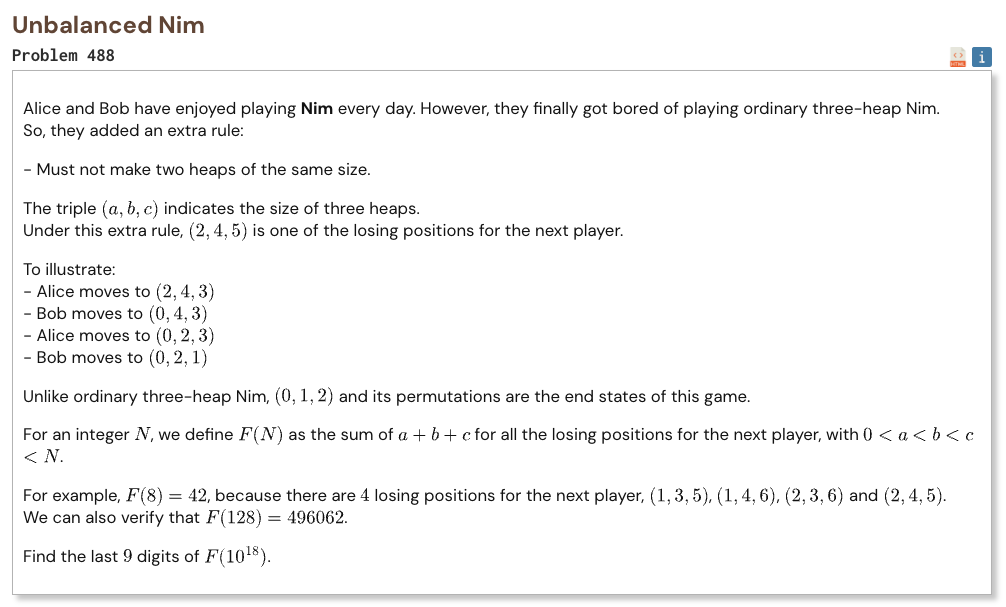

## Initial approach

- shift every heap size up by one to turn the losing condition into a normal xor condition
- once two shifted heap sizes are chosen, the third one is fixed by xor
- count ordered triples first because they are easier to handle
- use binary digit dynamic programming to enforce the large upper limit
- track both the number of valid triples and the sum of their heap sizes
- remove values below the allowed minimum with inclusion exclusion
- divide by six because every valid unordered triple appears in six different orders

In [1]:
%%time

N = 10**18
MOD = 10**9

def count_and_sum(A, B, C):
    bits = max(A, B, C).bit_length()
    dp = {(1, 1, 1): (1, 0)}

    for position in range(bits - 1, -1, -1):
        bit_a = (A >> position) & 1
        bit_b = (B >> position) & 1
        bit_c = (C >> position) & 1
        value = 1 << position

        next_dp = {}

        for state, data in dp.items():
            tight_a, tight_b, tight_c = state
            count, total = data

            for x_bit in (0, 1):
                if tight_a and x_bit > bit_a:
                    continue

                next_a = tight_a and x_bit == bit_a

                for y_bit in (0, 1):
                    if tight_b and y_bit > bit_b:
                        continue

                    next_b = tight_b and y_bit == bit_b
                    z_bit = x_bit ^ y_bit

                    if tight_c and z_bit > bit_c:
                        continue

                    next_c = tight_c and z_bit == bit_c
                    key = (next_a, next_b, next_c)

                    old_count, old_total = next_dp.get(key, (0, 0))

                    next_dp[key] = (
                        old_count + count,
                        old_total
                        + total
                        + count * (x_bit + y_bit + z_bit) * value
                    )

        dp = next_dp

    total_count = sum(
        count
        for count, total in dp.values()
    )

    total_sum = sum(
        total
        for count, total in dp.values()
    )

    return total_count, total_sum

def F(n):
    ordered_count = 0
    ordered_sum = 0

    for mask in range(8):
        A = 1 if mask & 1 else n
        B = 1 if mask & 2 else n
        C = 1 if mask & 4 else n

        count, total = count_and_sum(A, B, C)

        if mask.bit_count() % 2:
            ordered_count -= count
            ordered_sum -= total
        else:
            ordered_count += count
            ordered_sum += total

    return (
        ordered_sum - 3 * ordered_count
    ) // 6

assert F(8) == 42
assert F(128) == 496062

result = F(N) % MOD

print("Result:", result)

Result: 216737278
CPU times: user 1.29 ms, sys: 20 μs, total: 1.31 ms
Wall time: 1.32 ms
